In [ ]:
# To preprocess data
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import os
import glob
import cv2

# For metrics
from sklearn.metrics import accuracy_score,confusion_matrix,roc_curve,roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn import metrics


# For training
from tensorflow import config
from tensorflow import keras
from keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers
from tensorflow.keras.models import Model

# Data Preprocessing
## Preprocess için Kaggle'daki popüler notebooklardan birini takip ettim.
[Data Preprocessing Steps For Chest X-Ray Dataset](https://www.kaggle.com/code/jonaspalucibarbosa/chest-x-ray-pneumonia-cnn-transfer-learning#Custom-CNN)

In [ ]:
# save main path
xray_path = "/content/drive/MyDrive/Colab Notebooks/xray_dataset"

# concatenate train and test paths individually
train_path = os.path.join(xray_path,"train")
test_path=os.path.join(xray_path,"test")

# read and write every image path to lists
train_normal = glob.glob(train_path+"/NORMAL/*.jpeg")
train_pneumonia = glob.glob(train_path+"/PNEUMONIA/*.jpeg")

test_normal = glob.glob(test_path+"/NORMAL/*.jpeg")
test_pneumonia = glob.glob(test_path+"/PNEUMONIA/*.jpeg")

In [ ]:
type(train_normal)

list

In [ ]:
# create complete training list containing image paths
train_list = [x for x in train_normal]
train_list.extend([x for x in train_pneumonia])

# create training DataFrame object of image class and image path
df_train = pd.DataFrame(np.concatenate([['Normal']*len(train_normal) , ['Pneumonia']*len(train_pneumonia)]), columns = ['class'])
df_train['image'] = [x for x in train_list]


In [ ]:
df_train

,class,image
0,Normal,/content/drive/MyDrive/Colab Notebooks/xray_da...
1,Normal,/content/drive/MyDrive/Colab Notebooks/xray_da...
2,Normal,/content/drive/MyDrive/Colab Notebooks/xray_da...
3,Normal,/content/drive/MyDrive/Colab Notebooks/xray_da...
4,Normal,/content/drive/MyDrive/Colab Notebooks/xray_da...
...,...,...
5227,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
5228,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
5229,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
5230,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...


In [ ]:
df_train.describe()

,class,image
count,5232,5232
unique,2,5232
top,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
freq,3883,1


In [ ]:
df_train["class"].value_counts()

Pneumonia    3883
Normal       1349
Name: class, dtype: int64

In [ ]:
test_list = [x for x in test_normal]
test_list.extend([x for x in test_pneumonia])

df_test = pd.DataFrame(np.concatenate([['Normal']*len(test_normal) , ['Pneumonia']*len(test_pneumonia)]), columns = ['class'])
df_test['image'] = [x for x in test_list]

In [ ]:
df_test

,class,image
0,Normal,/content/drive/MyDrive/Colab Notebooks/xray_da...
1,Normal,/content/drive/MyDrive/Colab Notebooks/xray_da...
2,Normal,/content/drive/MyDrive/Colab Notebooks/xray_da...
3,Normal,/content/drive/MyDrive/Colab Notebooks/xray_da...
4,Normal,/content/drive/MyDrive/Colab Notebooks/xray_da...
...,...,...
619,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
620,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
621,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
622,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...


In [ ]:
df_test["class"].value_counts()

Pneumonia    390
Normal       234
Name: class, dtype: int64

random pneumonia image


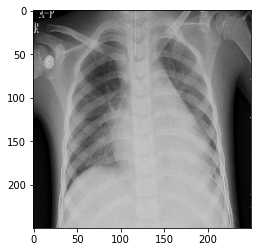

In [ ]:
print("random pneumonia image")

img = cv2.imread(train_pneumonia[75])
img = cv2.resize(img,(250,250))

plt.imshow(img)


random normal image


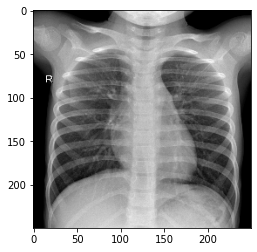

In [ ]:
print("random normal image")

img = cv2.imread(train_normal[75])
img = cv2.resize(img,(250,250))

plt.imshow(img)

In [ ]:
# Setting global variables for preprocessing and training
SEED = 16
BATCH_SIZE = 16
IMG_SIZE = 224

# train-val split with validation size of 0.2
train,val = train_test_split(df_train,test_size=0.2,random_state=SEED,stratify=df_train['class'])


In [ ]:
train

,class,image
1922,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
3248,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
4000,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
1540,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
3502,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
...,...,...
2647,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
3592,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
5164,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
2536,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...


In [ ]:
val

,class,image
3747,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
3036,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
1186,Normal,/content/drive/MyDrive/Colab Notebooks/xray_da...
4589,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
1933,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
...,...,...
1342,Normal,/content/drive/MyDrive/Colab Notebooks/xray_da...
4509,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...
91,Normal,/content/drive/MyDrive/Colab Notebooks/xray_da...
4166,Pneumonia,/content/drive/MyDrive/Colab Notebooks/xray_da...


In [ ]:
# Data Preprocess
# first default preprocess on train only horizontal flip on random probability.
generator_train = ImageDataGenerator(rescale=1/255.0,
                               horizontal_flip = True)

# Only rescale validation and test data
generator_test = ImageDataGenerator(rescale=1/255.0)

post_train = generator_train.flow_from_dataframe(train,
                                           x_col = 'image',
                                           y_col='class',
                                           target_size = (IMG_SIZE,IMG_SIZE),
                                           class_mode = 'binary',
                                           seed = SEED,
                                           batch_size = BATCH_SIZE
                                           )

post_val = generator_test.flow_from_dataframe(val,
                                           x_col = 'image',
                                           y_col='class',
                                           target_size = (IMG_SIZE,IMG_SIZE),
                                           class_mode = 'binary',
                                           seed = SEED,
                                           batch_size = BATCH_SIZE
                                           )

post_test = generator_test.flow_from_dataframe(df_test,
                                           x_col = 'image',
                                           y_col='class',
                                           target_size = (IMG_SIZE,IMG_SIZE),
                                           class_mode = 'binary',
                                           seed = SEED,
                                           batch_size = 1,
                                           shuffle=False
                                           )




Found 4185 validated image filenames belonging to 2 classes.
Found 1047 validated image filenames belonging to 2 classes.
Found 624 validated image filenames belonging to 2 classes.


# Birinci Model
## İlk modeli 3 konvolüsyon bloğundan ve 2 fully connected layer'dan oluşturdum. Çıkışta ise tek bir nöron olup aktivasyon fonksiyonu olarak sigmoid tercih ettim. Hiçbir omurga model kullanmadım. Epoch sayısını 5 olarak ayarladım. Rastgele oluşturduğum bir modelin nasıl sonuç aldığını görmek istedim.



In [ ]:
# created a custom cnn model

def model1():
    input = layers.Input(shape=(IMG_SIZE,IMG_SIZE,3))

    x = layers.Conv2D(filters=16,kernel_size=3)(input)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPool2D()(x)
    #x = layers.Dropout(0.1)(x)

    x = layers.Conv2D(filters=64,kernel_size=3)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPool2D()(x)
    x = layers.Dropout(0.2)(x)

    x = layers.Conv2D(filters=128,kernel_size=3)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPool2D()(x)
    x = layers.Dropout(0.3)(x)


    x = layers.Flatten()(x)
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.3)(x)


    x = layers.Dense(16, activation='relu')(x)
    x = layers.Dropout(0.2)(x)

    output = layers.Dense(1,activation='sigmoid')(x)

    return keras.Model(inputs=[input],outputs = output)





In [ ]:
keras.backend.clear_session()

train_model = model1()

train_model.compile(loss='binary_crossentropy',
                    optimizer = keras.optimizers.Adam(learning_rate=3e-5),
                    metrics='binary_accuracy')
# 2M trainable parameters
train_model.summary()

In [ ]:
config.list_physical_devices('GPU')

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [ ]:
# Trained on low learning rate with 5 epoch.
history = train_model.fit(post_train,
          batch_size = BATCH_SIZE, epochs = 5,
          validation_data=post_val,
          steps_per_epoch=(len(train)/BATCH_SIZE),
          validation_steps=(len(val)/BATCH_SIZE))


Epoch 1/5
261/261 [==============================] - 914s 3s/step - loss: 0.3646 - binary_accuracy: 0.8399 - val_loss: 0.6675 - val_binary_accuracy: 0.7421
Epoch 2/5
261/261 [==============================] - 77s 294ms/step - loss: 0.2061 - binary_accuracy: 0.9121 - val_loss: 0.2921 - val_binary_accuracy: 0.8644
Epoch 3/5
261/261 [==============================] - 77s 295ms/step - loss: 0.1600 - binary_accuracy: 0.9329 - val_loss: 0.1049 - val_binary_accuracy: 0.9647
Epoch 4/5
261/261 [==============================] - 80s 304ms/step - loss: 0.1400 - binary_accuracy: 0.9462 - val_loss: 0.0926 - val_binary_accuracy: 0.9618
Epoch 5/5
261/261 [==============================] - 77s 293ms/step - loss: 0.1373 - binary_accuracy: 0.9467 - val_loss: 0.0984 - val_binary_accuracy: 0.9685


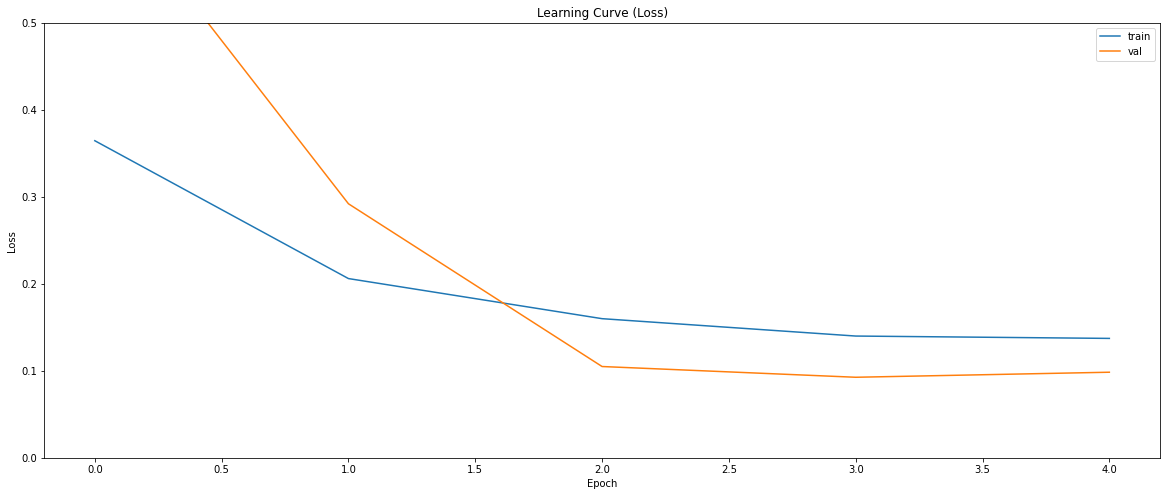

In [ ]:
fig, ax = plt.subplots(figsize=(10,8))
sns.lineplot(x = history.epoch, y = history.history['loss'])
sns.lineplot(x = history.epoch, y = history.history['val_loss'])
ax.set_title('Learning Curve (Loss)')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.set_ylim(0, 0.5)
ax.legend(['train', 'val'], loc='best')
plt.show()

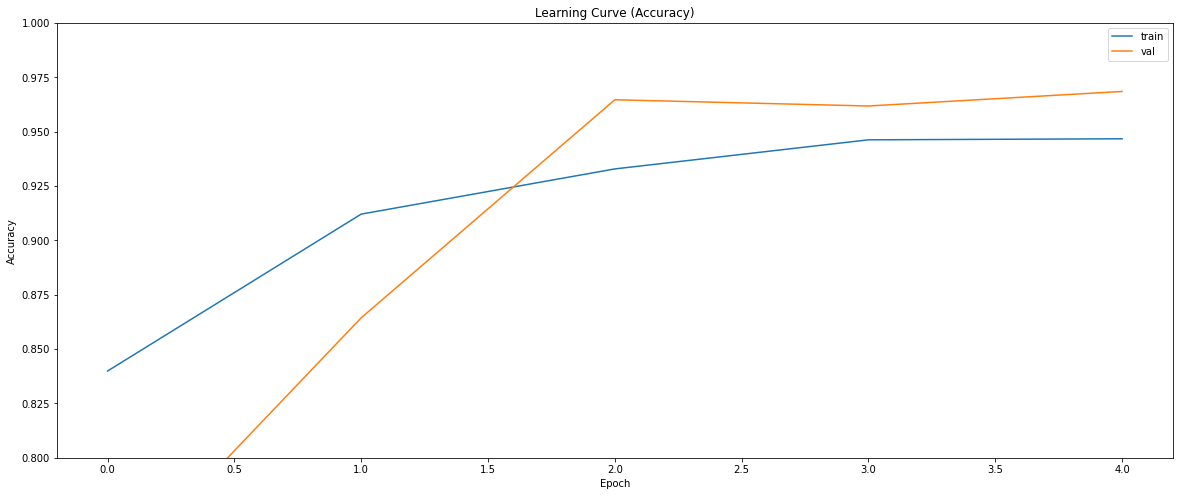

In [ ]:
fig, ax = plt.subplots(figsize=(10,8))
sns.lineplot(x = history.epoch, y = history.history['binary_accuracy'])
sns.lineplot(x = history.epoch, y = history.history['val_binary_accuracy'])
ax.set_title('Learning Curve (Accuracy)')
ax.set_ylabel('Accuracy')
ax.set_xlabel('Epoch')
ax.set_ylim(0.80, 1.0)
ax.legend(['train', 'val'], loc='best')
plt.show()

In [ ]:
score = train_model.evaluate(post_val, steps = len(val)/BATCH_SIZE, verbose = 0)
print('Val loss:', score[0])
print('Val accuracy:', score[1])

Val loss: 0.09839294850826263
Val accuracy: 0.9684813618659973


In [ ]:
score_test = train_model.evaluate(post_test, steps = len(post_test), verbose = 0)

print('Test loss:', score_test[0])
print('Test accuracy:', score_test[1])

Test loss: 0.5168485641479492
Test accuracy: 0.7804487347602844


Rastgele oluşturduğum CNN modelim overfit oldu. ve %78 test accuracy elde ettim

In [ ]:
train_model.save('/content/drive/MyDrive/Colab Notebooks')

INFO:tensorflow:Assets written to: /content/drive/MyDrive/Colab Notebooks/assets


In [ ]:
train_model_loaded = keras.models.load_model('/content/drive/MyDrive/Colab Notebooks')

# Birinci Model Metrikleri

## Confusion Matrix oluşturup modelin precision ve recall değerleri incelenmiştir.

In [ ]:
preds = train_model_loaded.predict(post_test,steps=len(post_test))


In [ ]:
# listing labels with normal as 0 and pneumonia as 1
num_label = {'Normal': 0, 'Pneumonia' : 1}
ground_truth = df_test['class'].copy().map(num_label).astype('int')

In [ ]:
# setting default threshold for binary classification
pred_labels= np.where(preds>0.5, 1, 0)

In [ ]:
print(metrics.classification_report(ground_truth, pred_labels, labels = [0, 1]))

              precision    recall  f1-score   support

           0       0.99      0.42      0.59       234
           1       0.74      1.00      0.85       390

    accuracy                           0.78       624
   macro avg       0.87      0.71      0.72       624
weighted avg       0.83      0.78      0.75       624



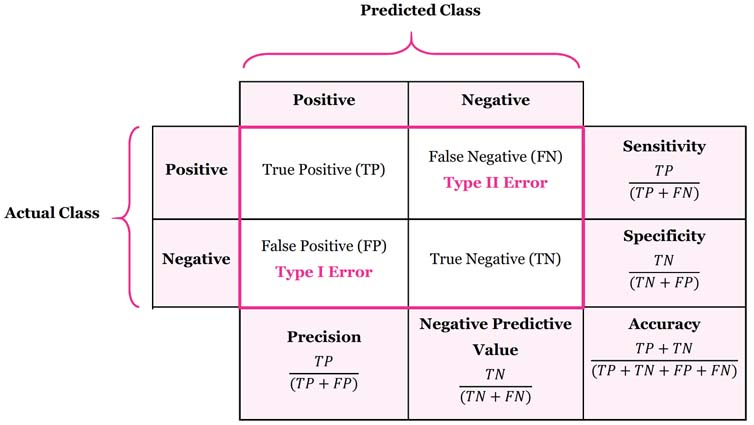

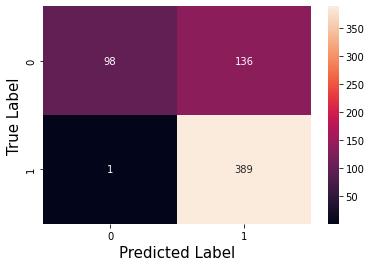

In [ ]:
confusion = confusion_matrix(ground_truth,pred_labels)
sns.heatmap(confusion,annot=True,fmt='d')
plt.xlabel("Predicted Label", fontsize= 15)
plt.ylabel("True Label", fontsize= 15)

plt.show()

Oluşturduğum rastgele model pneumonia hastalarının tamamına doğru teşhis koymuş(389-390). Fakat normal hastaların çoğuna pneumonia teşhisi koymuştur (recall = 0.42)

In [ ]:
# maximizes the normal recall value if set as threshold
roc_auc = metrics.roc_auc_score(ground_truth,preds)
print('ROC_AUC Score: ', roc_auc)


ROC_AUC Score:  0.9793556870479948


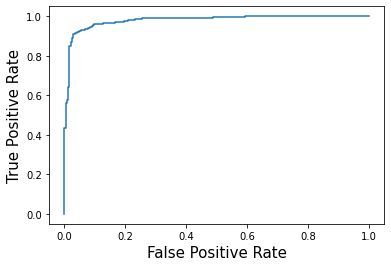

In [ ]:
fpr,tpr,thresh = roc_curve(ground_truth, preds)
plt.plot(fpr, tpr, roc_auc)

plt.xlabel("False Positive Rate", fontsize= 15)
plt.ylabel("True Positive Rate", fontsize= 15)

plt.show()


# İkinci Model

## Bu modelde ResNet50 mimarisini omurga olarak kullanıp üstüne 1 konvolüsyon bloğu ve Dense Layer ekledim. Herhangi bir hiperparametre düzeltmesi yapmadan modeli 20 epoch eğittim.


## Okuduğum makalede X-Ray Pneumonia Detection problemi ResNet50'nin omurga olarak kullanıldığı model farklı omurga kullanılan modellerden daha iyi performans göstermiştir.

[A deep learning approach with different optimizers and transfer learning architectures](https://www.sciencedirect.com/science/article/abs/pii/S0263224121008885#:~:text=Highlights&text=A%20deep%20learning%20method%20is,learning%20to%20classify%20Pneumonia%20patients.&text=Preparing%20a%20dataset%20of%20around,ray%20images%20for%20pneumonia%20detection.&text=The%20proposed%20deep%20transfer%20learning,of%20chest%20x%2Dray%20images)

In [ ]:
from pandas.core.dtypes.common import classes
def model2():
    base_model = keras.applications.ResNet50(include_top = False,
                                             input_shape = (IMG_SIZE,IMG_SIZE,3))

    base_model.trainable = False

    # Define Forward Pass

    input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    x = base_model(input,training=False)

    x = layers.Conv2D(filters=16,kernel_size=3)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPool2D()(x)
    x = layers.Dropout(0.1)(x)

    x = layers.Flatten()(x)
    x = layers.Dense(16, activation='relu')(x)
    x = layers.Dropout(0.2)(x)

    output = layers.Dense(1,activation='sigmoid')(x)

    return keras.Model(input,output)

In [ ]:
keras.backend.clear_session()

ResNet50_model = model2()

ResNet50_model.compile(loss='binary_crossentropy',
                    optimizer = keras.optimizers.Adam(learning_rate=2e-5),
                    metrics='binary_accuracy')

ResNet50_model.summary()

In [ ]:
history2 = ResNet50_model.fit(post_train,
          batch_size = BATCH_SIZE, epochs = 20,
          validation_data=post_val,
          steps_per_epoch=(len(train)/BATCH_SIZE),
          validation_steps=(len(val)/BATCH_SIZE))

In [ ]:
score_val_ResNet50 = ResNet50_model.evaluate(post_val, steps = len(val)/BATCH_SIZE, verbose = 0)
print('Val loss:', score_val_ResNet50[0])
print('Val accuracy:', score_val_ResNet50[1])


Val loss: 0.12210630625486374
Val accuracy: 0.9531996250152588


In [ ]:
score_test_ResNet50 = ResNet50_model.evaluate(post_test, steps = len(post_test), verbose = 0)
print('Test loss:', score_test_ResNet50[0])
print('Test accuracy:', score_test_ResNet50[1])


Test loss: 0.41044214367866516
Test accuracy: 0.8301281929016113


In [ ]:
ResNet50_model.save('/content/drive/MyDrive/Colab Notebooks/ResNet50_backbone_v1')

INFO:tensorflow:Assets written to: /content/drive/MyDrive/Colab Notebooks/ResNet50_backbone_v1/assets


In [ ]:
ResNet50_backbone_v1 = keras.models.load_model('/content/drive/MyDrive/Colab Notebooks/ResNet50_backbone_v1')

In [ ]:
preds_ResNet50_v1 = ResNet50_backbone_v1.predict(post_test,steps=len(post_test))

In [ ]:
num_label = {'Normal': 0, 'Pneumonia' : 1}
ground_truth = df_test['class'].copy().map(num_label).astype('int')

In [ ]:
pred_labels_ResNet50_v1= np.where(preds_ResNet50_v1>0.5, 1, 0)

In [ ]:
print(metrics.classification_report(ground_truth, pred_labels_ResNet50_v1, labels = [0, 1]))

              precision    recall  f1-score   support

           0       0.95      0.59      0.73       234
           1       0.80      0.98      0.88       390

    accuracy                           0.83       624
   macro avg       0.87      0.78      0.80       624
weighted avg       0.85      0.83      0.82       624



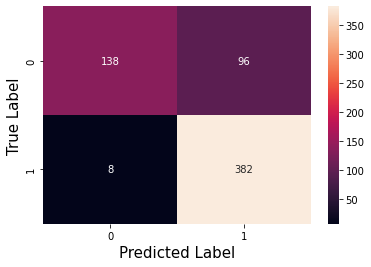

In [ ]:
confusion = confusion_matrix(ground_truth,pred_labels_ResNet50_v1)
sns.heatmap(confusion,annot=True,fmt='d')
plt.xlabel("Predicted Label", fontsize= 15)
plt.ylabel("True Label", fontsize= 15)

plt.show()

ResNet50 üstüne oluşturduğum bu modelin precision ve recall değerleri ilk modele kıyasla daha fazla olsa da yine de ideal bir model değil.

In [ ]:
roc_auc = metrics.roc_auc_score(ground_truth,preds_ResNet50_v1)
print('ROC_AUC Score: ', roc_auc)

ROC_AUC Score:  0.9617685733070348


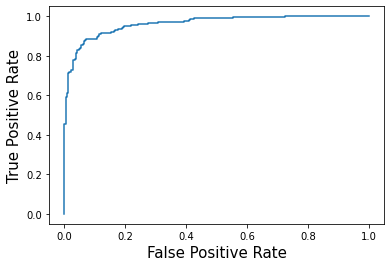

In [ ]:
fpr,tpr,thresh = roc_curve(ground_truth, preds_ResNet50_v1)
plt.plot(fpr, tpr, roc_auc)

plt.xlabel("False Positive Rate", fontsize= 15)
plt.ylabel("True Positive Rate", fontsize= 15)

plt.show()

# 3. Model
## Bu modelde tekrar ResNet50 kullandım. Bunun üzerine training sırasında hyperparameter tuning uyguladım ve modeli 30 epoch eğittim.

In [ ]:
base_model1 = keras.applications.ResNet50(include_top = False,
                                             input_shape = (IMG_SIZE,IMG_SIZE,3))

base_model1.trainable = False


def model3():
    input = keras.Input(shape=(IMG_SIZE,IMG_SIZE,3))

    x = base_model1(input,training=False)




    x = layers.Conv2D(filters=128,kernel_size=3,padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPool2D()(x)
    x = layers.Dropout(0.1)(x)

    x = layers.Conv2D(filters=64,kernel_size=3,padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPool2D()(x)
    x = layers.Dropout(0.1)(x)




    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.2)(x)

    x = layers.Dense(16, activation='relu')(x)
    x = layers.Dropout(0.1)(x)

    output = layers.Dense(1,activation='sigmoid')(x)

    return keras.Model(input,output)




In [ ]:
keras.backend.clear_session()

ResNet50_v2_model = model3()

ResNet50_v2_model.compile(loss='binary_crossentropy',
                    optimizer = keras.optimizers.Adam(learning_rate=2e-3),
                    metrics='binary_accuracy')

ResNet50_v2_model.summary()

In [ ]:
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2,
                              patience=3, min_lr=1e-5)

In [ ]:
checkpoint = keras.callbacks.ModelCheckpoint(
    filepath ='/content/drive/MyDrive/Colab Notebooks/ResNet50_v2/checkpoint2',
    monitor='val_loss',
    verbose=0,
    save_best_only=True,
    save_weights_only=False,
    mode='auto',
    save_freq='epoch',
    options=None,
    initial_value_threshold=None,
)

In [ ]:
history3 = ResNet50_v2_model.fit(post_train,
          batch_size = BATCH_SIZE, epochs = 30,
          validation_data=post_val,
          callbacks=[reduce_lr,checkpoint],
          steps_per_epoch=(len(train)/BATCH_SIZE),
          validation_steps=(len(val)/BATCH_SIZE))

In [ ]:
score_val_ResNet50_v2 = ResNet50_v2_model.evaluate(post_val, steps = len(val)/BATCH_SIZE, verbose = 0)
print('Val loss:', score_val_ResNet50_v2[0])
print('Val accuracy:', score_val_ResNet50_v2[1])

Val loss: 0.09014417231082916
Val accuracy: 0.9656160473823547


In [ ]:
score_test_ResNet50_v2 = ResNet50_v2_model.evaluate(post_test, steps = len(post_test), verbose = 0)
print('Test loss:', score_test_ResNet50_v2[0])
print('Test accuracy:', score_test_ResNet50_v2[1])

Test loss: 0.545909583568573
Test accuracy: 0.8092948794364929


%80 test accuracy elde ettim. Bunun üzerine fine-tuning yaptım.

# Fine tuning ResNet50_v2

## ResNet50'nin bütün parametrelerini eğitilebilir hale getirip çok düşük learning rate kullanarak tekrar eğittim. Aynı zamanda eğittiğim data sete çok büyük oranda data augmentation uyguladım(shift,shear,zoom,rotate).

In [ ]:
ResNet50_v2 = keras.models.load_model('/content/drive/MyDrive/Colab Notebooks/ResNet50_v2/checkpoint2')


In [ ]:
ResNet50_v2.trainable = True

In [ ]:
ResNet50_v2.summary()

In [ ]:
finetune_datagen = ImageDataGenerator(
        rescale = 1/255.0,
        rotation_range=35,
        width_shift_range=0.2,
        height_shift_range=0.2,
        shear_range=0.1,
        zoom_range=0.2,
        horizontal_flip=True,
        fill_mode='nearest')

In [ ]:
new_train = finetune_datagen.flow_from_dataframe(train,
                                           x_col = 'image',
                                           y_col='class',
                                           target_size = (IMG_SIZE,IMG_SIZE),
                                           class_mode = 'binary',
                                           seed = SEED,
                                           batch_size = BATCH_SIZE
                                           )

Found 4185 validated image filenames belonging to 2 classes.


In [ ]:
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2,
                              patience=2, min_lr=1e-9)

In [ ]:
checkpoint = keras.callbacks.ModelCheckpoint(
    filepath ='/content/drive/MyDrive/Colab Notebooks/ResNet50_v2/finetune',
    monitor='val_loss',
    verbose=0,
    save_best_only=True,
    save_weights_only=False,
    mode='auto',
    save_freq='epoch',
    options=None,
    initial_value_threshold=None,
)

In [ ]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    min_delta=0,
    patience=3,
    verbose=0,
    mode='auto',
    baseline=None,
    restore_best_weights=False
)

In [ ]:
keras.backend.clear_session()

ResNet50_v2.compile(loss='binary_crossentropy',
                    optimizer = keras.optimizers.Adam(learning_rate=1e-6),
                    metrics='binary_accuracy')



In [ ]:
config.list_physical_devices('GPU')


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [ ]:
history_finetune = ResNet50_v2.fit(new_train,
          batch_size = BATCH_SIZE, epochs = 20,
          validation_data=post_val,
          callbacks=[reduce_lr,checkpoint],
          steps_per_epoch=(len(train)/BATCH_SIZE),
          validation_steps=(len(val)/BATCH_SIZE))

In [ ]:
score_test_ResNet50_v2 = ResNet50_v2.evaluate(post_test, steps = len(post_test), verbose = 0)
print('Test loss:', score_test_ResNet50_v2[0])
print('Test accuracy:', score_test_ResNet50_v2[1])


Test loss: 0.28728318214416504
Test accuracy: 0.8782051205635071


In [ ]:
ResNet50_v2.save('/content/drive/MyDrive/Colab Notebooks/ResNet50_v2/best_test_acc')

INFO:tensorflow:Assets written to: /content/drive/MyDrive/Colab Notebooks/ResNet50_v2/best_test_acc/assets


In [ ]:
best_finetune_model = keras.models.load_model('/content/drive/MyDrive/Colab Notebooks/ResNet50_v2/finetune')

In [ ]:
best_finetune = best_finetune_model.evaluate(post_test, steps = len(post_test), verbose = 0)
print('Test loss:', best_finetune[0])
print('Test accuracy:', best_finetune[1])

Test loss: 0.2962365448474884
Test accuracy: 0.870192289352417


In [ ]:
preds = ResNet50_v2.predict(post_test,steps=len(post_test))

In [ ]:
num_label = {'Normal': 0, 'Pneumonia' : 1}
ground_truth = df_test['class'].copy().map(num_label).astype('int')

In [ ]:
roc_auc = metrics.roc_auc_score(ground_truth,preds)
print('ROC_AUC Score: ', roc_auc)

ROC_AUC Score:  0.954043392504931


In [ ]:
pred_labels= np.where(preds>0.5, 1, 0)

In [ ]:
print(metrics.classification_report(ground_truth, pred_labels, labels = [0, 1]))

              precision    recall  f1-score   support

           0       0.80      0.90      0.85       234
           1       0.94      0.86      0.90       390

    accuracy                           0.88       624
   macro avg       0.87      0.88      0.87       624
weighted avg       0.88      0.88      0.88       624



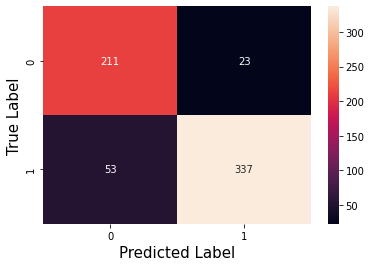

In [ ]:
confusion = confusion_matrix(ground_truth,pred_labels)
sns.heatmap(confusion,annot=True,fmt='d')
plt.xlabel("Predicted Label", fontsize= 15)
plt.ylabel("True Label", fontsize= 15)

plt.show()

## Görüldüğü üzere Fine Tune işleminde training ve validation accuracy'ler düşük olsa dahi %88 test accuracy elde ettim. Bunun yanı sıra modelin precision ve recall değerlerinde de gelişme kaydettim.

# Dördüncü Model
## Bu modelde EfficientNetV2S kullanıp aynı bir önceki modeldeki gibi fine tune ettim.

In [ ]:
base_model2 = keras.applications.EfficientNetV2S(include_top = False,
                                             input_shape = (IMG_SIZE,IMG_SIZE,3))

base_model2.trainable = False


def model4():
    input = keras.Input(shape=(IMG_SIZE,IMG_SIZE,3))

    x = base_model2(input,training=False)




    x = layers.Conv2D(filters=128,kernel_size=3,padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPool2D()(x)
    x = layers.Dropout(0.2)(x)

    x = layers.Conv2D(filters=64,kernel_size=3,padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPool2D()(x)
    x = layers.Dropout(0.2)(x)


    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.2)(x)

    x = layers.Dense(16, activation='relu')(x)
    x = layers.Dropout(0.1)(x)

    output = layers.Dense(1,activation='sigmoid')(x)

    return keras.Model(input,output)


In [ ]:
keras.backend.clear_session()

EfficientNetV2S = model4()

EfficientNetV2S.compile(loss='binary_crossentropy',
                    optimizer = keras.optimizers.Adam(learning_rate=2e-3),
                    metrics='binary_accuracy')

EfficientNetV2S.summary()

In [ ]:
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2,
                              patience=3, min_lr=1e-5)

In [ ]:
checkpoint = keras.callbacks.ModelCheckpoint(
    filepath ='/content/drive/MyDrive/Colab Notebooks/EfficientNetV2S/fit1',
    monitor='val_loss',
    verbose=0,
    save_best_only=True,
    save_weights_only=False,
    mode='auto',
    save_freq='epoch',
    options=None,
    initial_value_threshold=None,
)

In [ ]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    min_delta=0,
    patience=3,
    verbose=0,
    mode='auto',
    baseline=None,
    restore_best_weights=False
)

In [ ]:
history_EfficientNetV2S = EfficientNetV2S.fit(new_train,
          batch_size = BATCH_SIZE, epochs = 30,
          validation_data=post_val,
          callbacks=[reduce_lr,checkpoint,early_stop],
          steps_per_epoch=(len(train)/BATCH_SIZE),
          validation_steps=(len(val)/BATCH_SIZE))

Epoch 1/30
261/261 [==============================] - 313s 1s/step - loss: 0.5587 - binary_accuracy: 0.7341 - val_loss: 0.4822 - val_binary_accuracy: 0.7421 - lr: 0.0020
Epoch 2/30
261/261 [==============================] - 323s 1s/step - loss: 0.4212 - binary_accuracy: 0.7797 - val_loss: 0.4011 - val_binary_accuracy: 0.8472 - lr: 0.0020
Epoch 3/30
261/261 [==============================] - 281s 1s/step - loss: 0.3911 - binary_accuracy: 0.8179 - val_loss: 0.3662 - val_binary_accuracy: 0.8558 - lr: 0.0020
Epoch 4/30
261/261 [==============================] - 292s 1s/step - loss: 0.3678 - binary_accuracy: 0.8296 - val_loss: 0.3143 - val_binary_accuracy: 0.8634 - lr: 0.0020
Epoch 5/30
261/261 [==============================] - 142s 543ms/step - loss: 0.3522 - binary_accuracy: 0.8373 - val_loss: 0.3144 - val_binary_accuracy: 0.8653 - lr: 0.0020
Epoch 6/30
261/261 [==============================] - 143s 545ms/step - loss: 0.3585 - binary_accuracy: 0.8370 - val_loss: 0.3600 - val_binary_accu

In [ ]:
EfficientNetV2S_score = EfficientNetV2S.evaluate(post_test, steps = len(post_test), verbose = 1)

624/624 [==============================] - 35s 56ms/step - loss: 0.4806 - binary_accuracy: 0.8013


In [ ]:
print('Test loss:', EfficientNetV2S_score[0])
print('Test accuracy:', EfficientNetV2S_score[1])

Test loss: 0.480561226606369
Test accuracy: 0.8012820482254028


In [ ]:
EfficientNetV2S.trainable = True

EfficientNetV2S.compile(loss='binary_crossentropy',
                    optimizer = keras.optimizers.Adam(learning_rate=2e-5),
                    metrics='binary_accuracy')

EfficientNetV2S.summary()

In [ ]:
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2,
                              patience=2, min_lr=1e-7)

In [ ]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    min_delta=0,
    patience=4,
    verbose=0,
    mode='auto',
    baseline=None,
    restore_best_weights=False
)

In [ ]:
checkpoint = keras.callbacks.ModelCheckpoint(
    filepath ='/content/drive/MyDrive/Colab Notebooks/EfficientNetV2S/finetune',
    monitor='val_loss',
    verbose=0,
    save_best_only=True,
    save_weights_only=False,
    mode='auto',
    save_freq='epoch',
    options=None,
    initial_value_threshold=None,
)

In [ ]:
history_EfficientNetV2S_finetune = EfficientNetV2S.fit(new_train,
          batch_size = BATCH_SIZE, epochs = 20,
          validation_data=post_val,
          callbacks=[reduce_lr,checkpoint,early_stop],
          steps_per_epoch=(len(train)/BATCH_SIZE),
          validation_steps=(len(val)/BATCH_SIZE))

In [ ]:
score_EfficientNetV2S = EfficientNetV2S.evaluate(post_test, steps = len(post_test), verbose = 1)
print('Test loss:', score_EfficientNetV2S [0])
print('Test accuracy:', score_EfficientNetV2S [1])

624/624 [==============================] - 38s 61ms/step - loss: 0.2224 - binary_accuracy: 0.9359
Test loss: 0.22241252660751343
Test accuracy: 0.9358974099159241


In [ ]:
preds = EfficientNetV2S.predict(post_test,steps=len(post_test))

In [ ]:
num_label = {'Normal': 0, 'Pneumonia' : 1}
ground_truth = df_test['class'].copy().map(num_label).astype('int')

In [ ]:
roc_auc = metrics.roc_auc_score(ground_truth,preds)
print('ROC_AUC Score: ', roc_auc)

ROC_AUC Score:  0.9778325662941049


In [ ]:
pred_labels= np.where(preds>0.5, 1, 0)

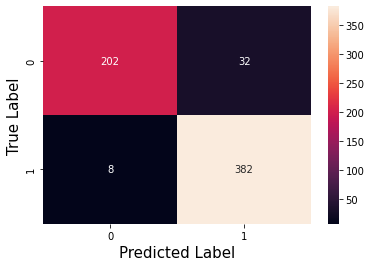

In [ ]:
confusion = confusion_matrix(ground_truth,pred_labels)
sns.heatmap(confusion,annot=True,fmt='d')
plt.xlabel("Predicted Label", fontsize= 15)
plt.ylabel("True Label", fontsize= 15)

plt.show()

In [ ]:
print(metrics.classification_report(ground_truth, pred_labels, labels = [0, 1]))

              precision    recall  f1-score   support

           0       0.96      0.86      0.91       234
           1       0.92      0.98      0.95       390

    accuracy                           0.94       624
   macro avg       0.94      0.92      0.93       624
weighted avg       0.94      0.94      0.94       624



## EfficientNetV2S üzerine oluşturduğum modeli fine tune ettikten sonra en iyi sonuçları elde ettim. Model 390 Pneumonia hastasının 382 tanesine doğru teşhis koymuş. Aynı zamanda 234 normal hastanın da 202 tanesine doğru teşhis koymuş.
